# Training a MACE model


In this notebook, the flow of training a MACE model is detailed step by step.



In [1]:
import matplotlib.pyplot    as plt
plt.ioff()
import numpy                as np
import torch
from time                   import time
import datetime             as dt
from tqdm                   import tqdm

from pathlib import Path
import sys

parentpath = str(Path().cwd())+'/'

print(parentpath)

sys.path.append(parentpath)

import src.mace.CSE_0D.dataset  as ds
import src.mace.CSE_0D.plotting as plotting
import src.mace.train           as train
import src.mace.test            as test
import src.mace.load            as load
import src.mace.mace            as mace
from src.mace.loss              import Loss
import src.mace.loss            as loss
import src.mace.utils           as utils
from src.mace.input             import Input

specs_dict = utils.get_specs()

%reload_ext autoreload
%autoreload 2

c:\Users\bartd\Documents\Astronomy\Thesis\MACE/


## Setting up

>***Note***:
>If you are training the architecture with your own data, you can set up the model in the following way. However, if you will follow the notebook, we will load a pre-trained model to continue the training, just for tutorial purposes. Then, skip the cells on "Set up the model".


### Naming the model
The default model to name the model is with the date and time of training. This can be adjusted with changing the parameter name.




In [2]:
now = dt.datetime.now()
name = str(now.strftime("%Y%m%d")+'_'+now.strftime("%H%M%S"))
name = "example_out_v2/" + name

path = parentpath + 'model/'+name

print(path)

c:\Users\bartd\Documents\Astronomy\Thesis\MACE/model/example_out_v2/20261109_104123


Make directories to store output and trained model.



In [3]:
utils.makeOutputDir(path)
utils.makeOutputDir(path+'/nn')
utils.makeOutputDir(path+'/figs')

'c:\\Users\\bartd\\Documents\\Astronomy\\Thesis\\MACE/model/example_out_v2/20261109_104123/figs'

### Reading input file
Fill in the name of the input file for arg.

For tutorial purposes, the amount of training data and training epochs is limited in this example.

In [4]:
arg = 'example_v2'

In [5]:
infile = parentpath+'input/'+arg+'.in'
input = Input(infile, name)
meta = input.make_meta(path)
input.print()

You forgot to give an input for ##
------------------------------
Name: example_out_v2/20261109_104123
------------------------------
     inputfile: c:\Users\bartd\Documents\Astronomy\Thesis\MACE/input/example_v2.in
   data type: CSE
       ae type: simple
# z dimensions: 8
        scheme: int
  # evolutions: 16
     loss type: abs_idn
      # epochs: 150
 learning rate: 0.0001



### Set up Pytorch

In [6]:
cuda   = False
DEVICE = torch.device("cuda" if cuda else "cpu")
batch_size = 1
kwargs = {'num_workers': 1, 'pin_memory': True}

### Set up the model


Make the model, randomly initialised.



In [7]:
model = mace.MACE(n_dim=input.n_dim, p_dim=4, z_dim=input.z_dim,
                  ae_type=input.ae_type, g_nn=False)

num_params = utils.count_parameters(model)
print(f'\nThe model has {num_params} trainable parameters')


The model has 284692 trainable parameters


### Load training & validation data

Load the train, validation, and test data sets.

In [8]:
traindata, testdata, data_loader, test_loader = ds.get_data(dt_fract=input.dt_fract,
                                                            nb_samples=input.nb_samples, batch_size=batch_size,
                                                            nb_test=input.nb_test,kwargs=kwargs, inpackage=True, data_type='1DCSE')

> Train state: True
Found paths: 13
[12  5  0  3 11  3  7  9  3  5]
number of test paths: 3
Selected test paths: 3
Selected paths: 7


> Train state: False
Found paths: 13
[12  5  0  3 11  3  7  9  3  5]
number of test paths: 3
Selected test paths: 3
Selected paths: 3


Dataset:
------------------------------
  total # of samples: 10
#   training samples: 7
# validation samples: 3
               ratio: 0.3
     #  test samples: 3


c:\Users\bartd\Documents\Astronomy\Thesis\MACE\src\mace\CSE_0D\dataset.py:262: UserWarning: Input line 14 contained no data and will not be counted towards `max_rows=50000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  paths = np.loadtxt(loc + 'data/paths_train_data.txt', dtype=str)


## Loading the pre-trained model


Setting the directory of the model.



In [10]:
outloc  = parentpath+'model/'
dirname = 'example_weights_v2'
epoch   = 7

In [11]:
state_dict = torch.load(f'model/{dirname}/nn/nn{epoch}.pt', map_location='cpu', weights_only=True)
model.load_state_dict(state_dict) ## strict: fails if any key is missing or unexpected
model.eval()

print(f'The model has {utils.count_parameters(model)} trainable parameters')

The model has 284692 trainable parameters


Loading the pre-trained model.



## Training the model

Training the model in [Maes et al. (2024)](https://ui.adsabs.harvard.edu/abs/2024arXiv240503274M/abstract) happens it two stages:

1. For the first few epochs (input.ini_epochs) the models is trained with unscaled losses.
2. The losses of the model are rescaled, normalised based in the losses in the first few epochs.

### Stage 1
Initialise loss.

In [9]:
trainloss = loss.setup_loss(input.losstype, [input.abs, input.idn])
validloss = loss.setup_loss(input.losstype, [input.abs, input.idn])

Train the model & time the training.

In [10]:
lr = input.lr
lr = 1e-4
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

In [11]:
train.train(model,
            data_loader, test_loader,
            trainloss, validloss,
            optimiser=optimizer, 
            nb_epochs=input.ini_epochs,
            nb_evol=input.nb_evol,
            batch_size=8)

c:\Users\bartd\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch 1/5:
 - Train Loss 1.345e-01 | Valid Loss 3.440e-02,
 - Failed solves 0/12464 | 27.3 s
Epoch 2/5:
 - Train Loss 3.325e-02 | Valid Loss 3.111e-02,
 - Failed solves 0/12464 | 29.6 s
Epoch 3/5:
 - Train Loss 3.012e-02 | Valid Loss 2.710e-02,
 - Failed solves 0/12464 | 30.2 s
Epoch 4/5:
 - Train Loss 2.844e-02 | Valid Loss 2.825e-02,
 - Failed solves 0/12464 | 30.7 s
Epoch 5/5:
 - Train Loss 2.590e-02 | Valid Loss 2.230e-02,
 - Failed solves 0/12464 | 35.2 s


Loss(
  (terms): ModuleDict(
    (abs): AbsLoss()
    (idn): IdnLoss()
  )
)

<Axes: xlabel='epoch', ylabel='loss'>

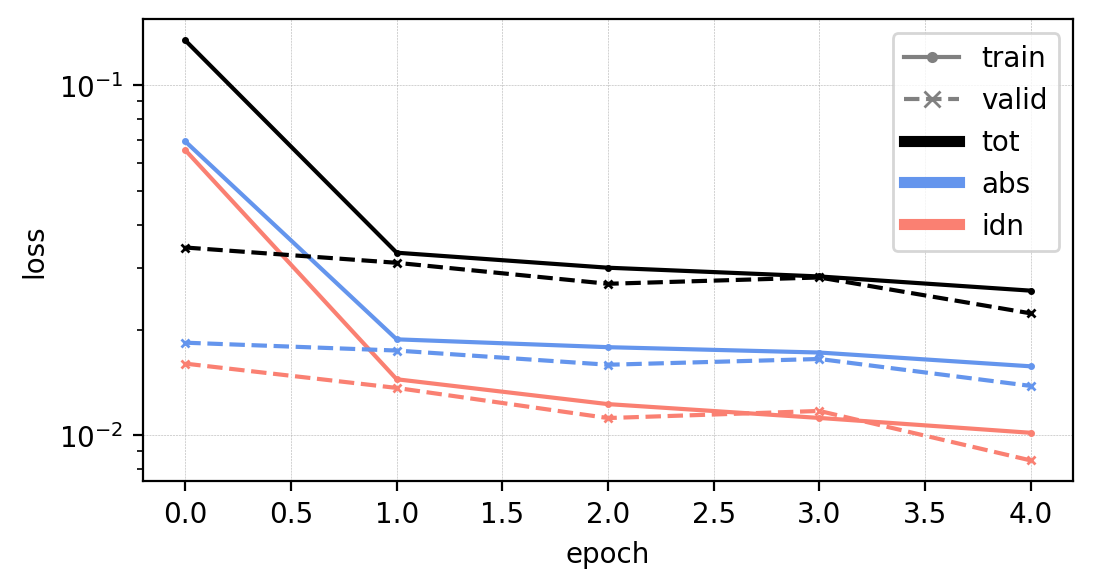

In [12]:
loss.plot({'train':trainloss, 'valid':validloss})

### Stage 2
Normalise losses.

In [13]:
trainloss.normalize()
validloss.normalize()

Continue the training. Use lower batch count initially.


In [ ]:
train.train(model,
            data_loader, test_loader,
            trainloss, validloss,
            optimiser=optimizer, 
            nb_epochs=30,
            nb_evol=input.nb_evol)

### Stage 3

Normalize losses again.

In [ ]:
trainloss.normalize()
validloss.normalize()

Continue training with full batches.

In [ ]:
train.train(model,
            data_loader, test_loader,
            trainloss, validloss,
            optimiser=optimizer, 
            nb_epochs=50,
            nb_evol=input.nb_evol)

Epoch 1/50:
 - Train Loss 1.002e-02 | Valid Loss 7.794e-03,
 - Failed solves 0/12464 | 10.9 s
Epoch 2/50:
 - Train Loss 7.366e-03 | Valid Loss 7.191e-03,
 - Failed solves 0/12464 | 10.5 s
Epoch 3/50:
 - Train Loss 6.572e-03 | Valid Loss 6.465e-03,
 - Failed solves 0/12464 | 10.0 s
Epoch 4/50:
 - Train Loss 6.129e-03 | Valid Loss 5.985e-03,
 - Failed solves 0/12464 | 10.6 s
Epoch 5/50:
 - Train Loss 5.880e-03 | Valid Loss 5.544e-03,
 - Failed solves 0/12464 | 10.1 s
Epoch 6/50:
 - Train Loss 5.489e-03 | Valid Loss 5.217e-03,
 - Failed solves 0/12464 | 10.2 s
Epoch 7/50:
 - Train Loss 5.313e-03 | Valid Loss 5.085e-03,
 - Failed solves 0/12464 | 10.2 s
Epoch 8/50:
 - Train Loss 5.101e-03 | Valid Loss 4.706e-03,
 - Failed solves 0/12464 | 10.4 s
Epoch 9/50:
 - Train Loss 4.920e-03 | Valid Loss 4.532e-03,
 - Failed solves 0/12464 | 10.4 s
Epoch 10/50:
 - Train Loss 4.818e-03 | Valid Loss 4.345e-03,
 - Failed solves 0/12464 | 10.3 s
Epoch 11/50:
 - Train Loss 4.625e-03 | Valid Loss 4.235e-03

Loss(
  (terms): ModuleDict(
    (abs): AbsLoss()
    (idn): IdnLoss()
  )
)

<Axes: xlabel='epoch', ylabel='loss'>

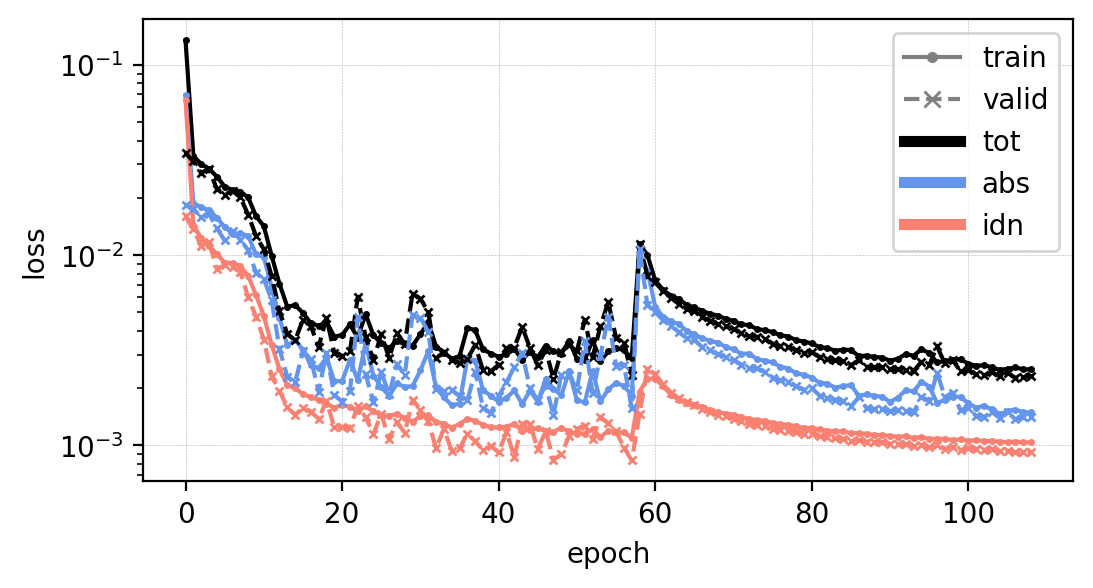

In [27]:
loss.plot({'train':trainloss, 'valid':validloss})

## Saving the model
Save the losses & specifics of the data set.

In [28]:
print('path:', path)

trainloss.save(path+'/train')
validloss.save(path+'/valid')

min_max = np.stack((traindata.mins, traindata.maxs), axis=1)
np.save(path+'/minmax', min_max)

path: c:\Users\bartd\Documents\Astronomy\Thesis\MACE/model/example_out_v2/20261109_104123


Save the model and the status of the solver (see [torchode status](https://github.com/martenlienen/torchode/blob/main/torchode/status_codes.py) for more details).

In [29]:
torch.save(model.state_dict(),path+'/nn/nn.pt')

#np.save(path+'/train/status', model.get_status('train')) # type: ignore
#np.save(path +'/valid/status', model.get_status('test') ) # type: ignore

Plot the evolution of the loss and save the figure.



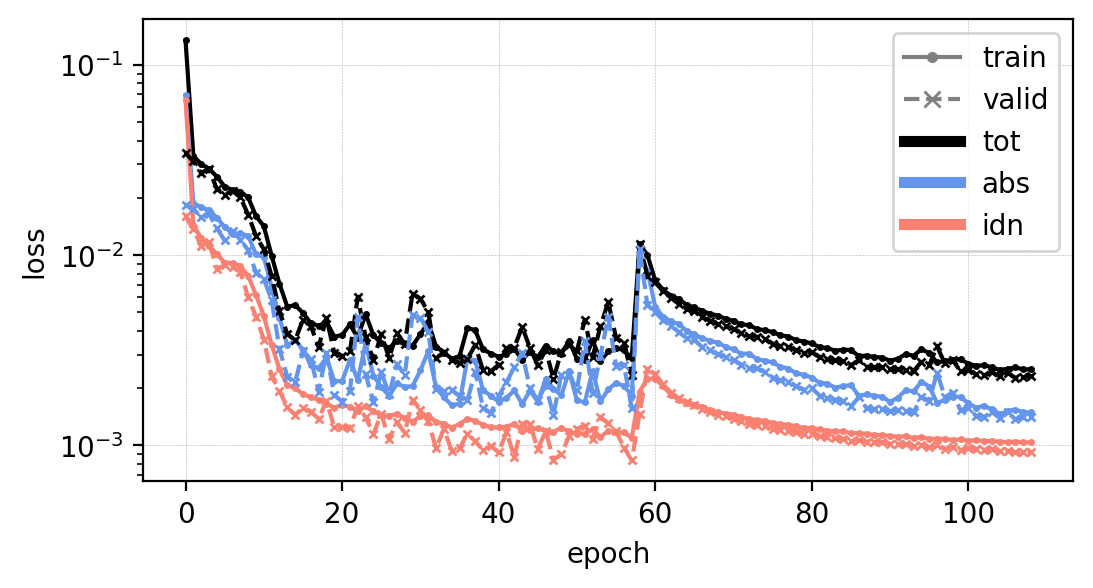

In [30]:
plt.close()
loss.plot({'train':trainloss, 'valid':validloss})
plt.savefig(path+'/figs/loss.png')
plt.show()

## Testing the model


Perform tests on the trained model to get an accuracy indication, according to the following error metric:

$$ {\rm error} = \frac{\log_{10}\boldsymbol{n}-\log_{10}\hat{\boldsymbol{n}}}{\log_{10}\boldsymbol{n}}, $$

which is executed element-wise and subsequently summed over the different chemical species

### Performing the tests
(tbd)

### Saving the outcome of the tests
The error saved is normalised over the amount of tests, given by len(traindata.testpath).

(tbd)

### Plotting abundances

In [31]:
testpath = 'mid_dens'
model1D, (n, p, dt), info = ds.get_test_data('1DCSE', testpath, meta, inpackage=True)

> Train state: False
Found paths: 13
[12  5  0  3 11  3  7  9  3  5]
number of test paths: 3
Selected test paths: 3
Selected paths: 3


c:\Users\bartd\Documents\Astronomy\Thesis\MACE\
-------------------
Input of test model
-------------------
Mdot [Msol/yr]:       1e-06
v [km/s]:             17.5
Density proxi Mdot/v: 5.714285714285714e-13

Temp at 1e16 cm [K]:  93.91
Tstar:                2100.0
eps:                  0.5
-------------------



c:\Users\bartd\Documents\Astronomy\Thesis\MACE\src\mace\CSE_0D\dataset.py:262: UserWarning: Input line 14 contained no data and will not be counted towards `max_rows=50000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  paths = np.loadtxt(loc + 'data/paths_train_data.txt', dtype=str)


In [32]:
tic = time()
with torch.no_grad():
    n_hat, status = model.rollout(n[0:1], p[None], dt[None])
toc = time()

n_evol = torch.cat((n[0:1], n_hat[0]), dim=0)      ## (N, 468)

print(f'Evolution of {n_hat.shape[1]} steps in {toc-tic:.2f} s')
print('Solver status counts [success, general error, dt_min, max_steps, inf. norm]:',
      torch.bincount(status.flatten(), minlength=5).tolist())

Evolution of 134 steps in 0.47 s
Solver status counts [success, general error, dt_min, max_steps, inf. norm]: [134, 0, 0, 0, 0]


In [33]:
n_real = ds.get_abs(n.numpy())
n_evol = ds.get_abs(n_evol.numpy())

err, err_evol = utils.error(n_real, n_evol)

print('Evolution error (Eq. 23):', np.round(err_evol, 3))

Evolution error (Eq. 23): 17.392


In [34]:
from importlib import reload
reload(plotting)

<module 'src.mace.CSE_0D.plotting' from 'c:\\Users\\bartd\\Documents\\Astronomy\\Thesis\\MACE\\src\\mace\\CSE_0D\\plotting.py'>

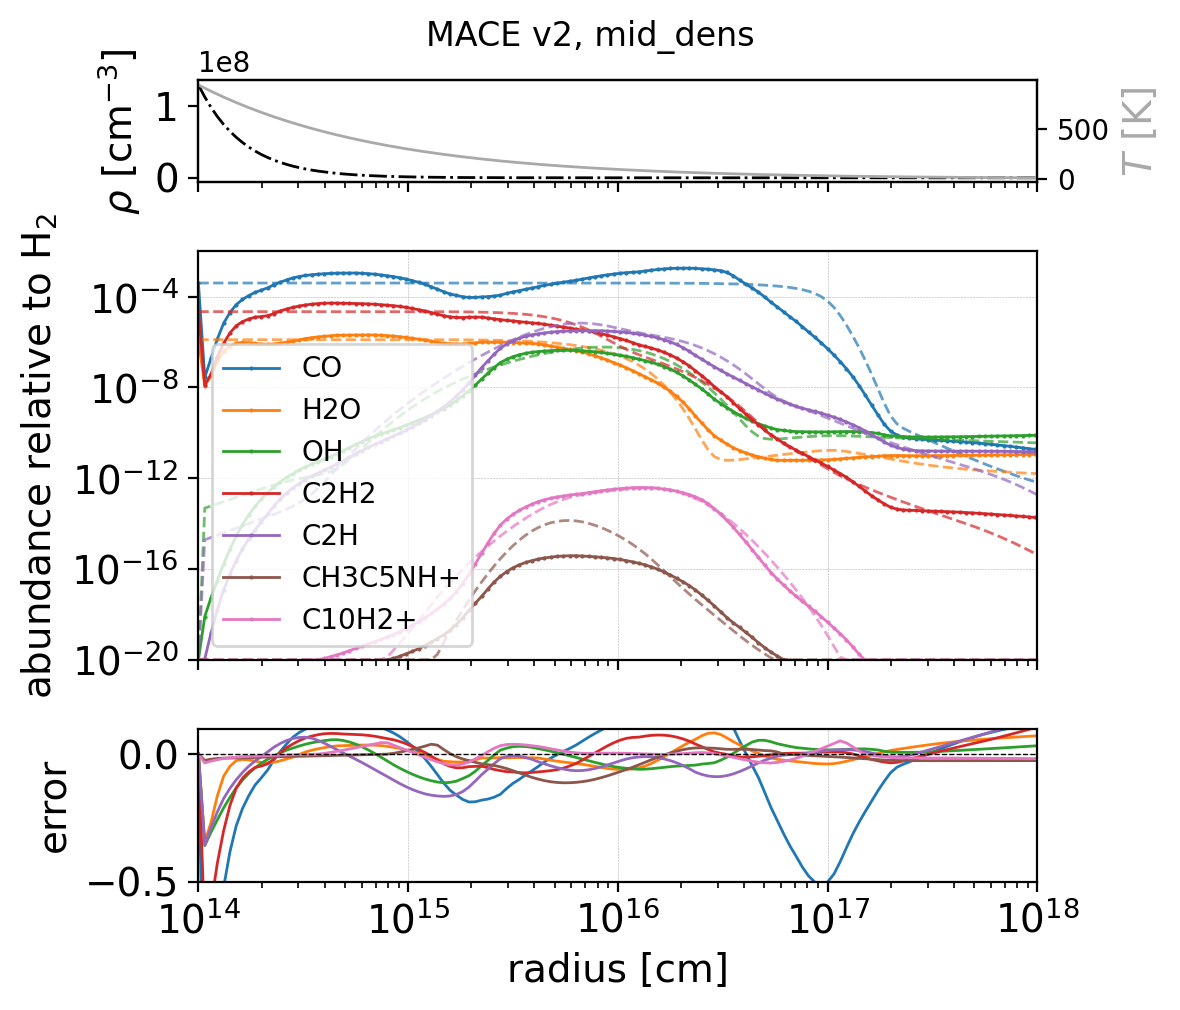

In [35]:
fig12_specs = ['CO', 'H2O', 'OH', 'C2H2', 'C2H', 'CH3C5NH+', 'C10H2+']

fig, axes = plotting.plot_abs(model1D, '1DCSE', n_real, n_evol, specs=fig12_specs, step=False)

axes[2].set_ylim(-.5,.1)
fig.suptitle(f'MACE v2, {testpath}', y=1.0)
fig.savefig(path+'/figs/preds.png')
plt.show()